<a href="https://colab.research.google.com/github/LeonSigal/SEGAN_MRSTFT/blob/main/SEGAN_MRSTFT_Colab_FINAL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SEGAN – Speech Enhancement Generative Adversarial Network
## Audio Denoising · 1D-CNN · Mel-Spectrograms · UrbanSound8K
**Course: Data Mining and Learning Systems**

---

## 1. Problem Formulation & Theoretical Framework

### 1.1 Formal Problem Definition

Let $x \in \mathbb{R}^T$ be a **clean speech signal** and $n \in \mathbb{R}^T$ a **noise signal**.
The observed **noisy signal** is:

$$y = x + n$$

The goal of **speech enhancement** is to learn a mapping $G: y \mapsto \hat{x}$ such that $\hat{x} \approx x$.

---

### 1.2 Mel-Spectrogram Representation

$$M = \text{MelFilterbank}\left(|\text{STFT}(y)|^2\right) \in \mathbb{R}^{F \times T}$$

where $F$ = mel bins, $T$ = time frames. Benefits: perceptual alignment, lower dimensionality.

---

### 1.3 GAN Objective

$$\min_G \max_D \;\; \mathbb{E}_{x}[\log D(y, x)] + \mathbb{E}_{y}[\log(1 - D(y, G(y)))]$$

**Combined Generator Loss:**

$$\mathcal{L}_G = \underbrace{\mathcal{L}_{GAN}}_{\text{adversarial}} + \lambda \cdot \underbrace{\|x - G(y)\|_1}_{L_1 \text{ reconstruction}}$$

$\lambda = 100$ enforces direct fidelity alongside perceptual quality.

---

### 1.4 U-Net Architecture (skip connections)

```
Noisy mel
  Enc1(64→16) ─────────────────────────── skip ─┐
  Enc2(16→32) ──────────────────── skip ─┐       │
  Enc3(32→64) ─────────── skip ─┐        │       │
  Enc4(64→128) ──── skip ─┐     │        │       │
  Enc5(128→256)─┐          │     │        │       │
  Bottleneck 512│          │     │        │       │
  Dec5◄──────────┘ cat     │     │        │       │
  Dec4◄────────────────────┘ cat │        │       │
  Dec3◄──────────────────────────┘ cat   │       │
  Dec2◄──────────────────────────────────┘ cat  │
  Dec1◄──────────────────────────────────────── ┘
  Tanh output
Enhanced mel
```

---

### 1.5 Pros & Cons

| Advantages | Limitations |
|------------|-------------|
| End-to-end learnable pipeline | Requires large paired training data |
| Perceptually driven GAN loss | Training instability possible |
| U-Net preserves spectral detail | Griffin-Lim inversion adds artifacts |
| Generalises to unseen noise | Fixed 128-frame segment length |
| Fast inference (one forward pass) | PESQ gains limited without fine-tuning |

---

### 1.6 Evaluation Metrics

| Metric | Range | Interpretation |
|--------|-------|---------------|
| PESQ | -0.5 to 4.5 | Perceptual speech quality (higher = better) |
| STOI | 0 to 1 | Short-time objective intelligibility (higher = better) |
| SNR (dB) | unbounded | Signal-to-noise ratio (higher = better) |

---


## 0. Environment Setup
> **Runtime → Change runtime type → T4 GPU** (free on Colab)

In [ ]:
import subprocess
r = subprocess.run(["nvidia-smi"], capture_output=True, text=True)
print(r.stdout if r.returncode == 0 else "No GPU found - using CPU")

Sun Jun 28 10:47:35 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   46C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
!pip install -q librosa soundfile pesq pystoi tqdm ipywidgets
import IPython; IPython.display.clear_output()
print("All packages installed")


All packages installed


## 2. Imports & Configuration

In [ ]:
import os, warnings, random, io
import numpy as np
import torch, torch.nn as nn, torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import librosa, librosa.display, soundfile as sf
import matplotlib.pyplot as plt
from pathlib import Path
from tqdm.notebook import tqdm
import IPython.display as ipd
import ipywidgets as widgets
from IPython.display import display, HTML

warnings.filterwarnings("ignore")
torch.manual_seed(42); np.random.seed(42)

SAMPLE_RATE    = 16000
N_FFT          = 512
HOP_LENGTH     = 128
N_MELS         = 64
SEGMENT_FRAMES = 128
BATCH_SIZE     = 16
EPOCHS         = 60
LR_G           = 2e-4
LR_D           = 2e-5
LAMBDA_L1      = 10
DEVICE         = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# --- Fixed mel-dB normalization range ---
# librosa.power_to_db(..., ref=np.max) always returns values in [-80, 0] dB
# by construction. Using ONE fixed affine map everywhere -- Dataset (both
# clean AND noisy), the loss functions, and inference -- guarantees that
# training targets and inference-time de-normalization always operate in
# the exact same numerical space. No per-utterance statistics are computed
# or threaded through the pipeline, so there is nothing that can drift out
# of sync between what the Generator is optimized against and how its
# output is decoded back into a spectrogram.
MEL_DB_MIN   = -80.0
MEL_DB_MAX   = 0.0
MEL_DB_RANGE = MEL_DB_MAX - MEL_DB_MIN  # 80.0

def normalize_mel_db(mel_db):
    """Fixed affine map: [-80, 0] dB -> [-1, 1]. Identical formula used for
    clean and noisy mels, at training time and at inference time."""
    return (2.0 * (mel_db - MEL_DB_MIN) / MEL_DB_RANGE) - 1.0

def denormalize_mel_db(mel_norm):
    """Inverse of normalize_mel_db. Identical formula everywhere."""
    return ((mel_norm + 1.0) / 2.0) * MEL_DB_RANGE + MEL_DB_MIN

if DEVICE.type == "cpu":
    print("\u26a0\ufe0f  WARNING: No GPU detected. Training will be very slow on CPU.")
    print("   Go to: Runtime -> Change runtime type -> T4 GPU")
else:
    print(f"\u2705 GPU ready: {torch.cuda.get_device_name(0)}")

print(f"Device         : {DEVICE}")
print(f"Sample Rate    : {SAMPLE_RATE} Hz")
print(f"Mel bins       : {N_MELS}")
print(f"Segment length : {SEGMENT_FRAMES} frames  ({SEGMENT_FRAMES*HOP_LENGTH/SAMPLE_RATE:.2f}s)")
print(f"Batch size     : {BATCH_SIZE}")
print(f"Epochs         : {EPOCHS}")

✅ GPU ready: Tesla T4
Device         : cuda
Sample Rate    : 16000 Hz
Mel bins       : 64
Segment length : 128 frames  (1.02s)
Batch size     : 16
Epochs         : 60


## 3. Data Preparation

Downloads **LibriSpeech test-clean** and **UrbanSound8K**. Falls back to synthetic noise if Kaggle is unavailable.

In [ ]:
import zipfile, tarfile, urllib.request, shutil

# --- Kaggle API authentication ---
# Generate a token at https://www.kaggle.com/settings -> API Tokens -> Generate New Token
import kagglehub
os.environ["KAGGLE_USERNAME"] = "YOUR_KAGGLE_USERNAME"
os.environ["KAGGLE_KEY"] = "YOUR_KAGGLE_KEY"
print("Kaggle credentials configured")

os.makedirs("data/clean", exist_ok=True)
os.makedirs("data/noise", exist_ok=True)
os.makedirs("checkpoints", exist_ok=True)

# LibriSpeech
LIBRI_URL = "https://www.openslr.org/resources/12/test-clean.tar.gz"
if not os.path.exists("LibriSpeech"):
    print("Downloading LibriSpeech test-clean (~346 MB)...")
    urllib.request.urlretrieve(LIBRI_URL, "test-clean.tar.gz")
    with tarfile.open("test-clean.tar.gz") as t: t.extractall(".")
    os.remove("test-clean.tar.gz")
    print("LibriSpeech extracted")
else:
    print("LibriSpeech already present")

flac_files = sorted(Path("LibriSpeech").glob("**/*.flac"))
print(f"Found {len(flac_files)} speech files - converting up to 500...")
for f in tqdm(flac_files[:500], desc="Converting flac to wav"):
    dst = Path("data/clean") / f.name.replace(".flac", ".wav")
    if not dst.exists():
        y, _ = librosa.load(str(f), sr=SAMPLE_RATE)
        sf.write(str(dst), y, SAMPLE_RATE)
print(f"Clean speech ready: {len(list(Path('data/clean').glob('*.wav')))} files")

# UrbanSound8K or synthetic fallback
try:
    import kagglehub
    path = kagglehub.dataset_download("chrisfilo/urbansound8k")
    wav_list = sorted(Path(path).glob("**/*.wav"))[:1000]
    for f in wav_list:
        dst = Path("data/noise") / f.name
        if not dst.exists(): shutil.copy(str(f), str(dst))
    print(f"UrbanSound8K ready: {len(list(Path('data/noise').glob('*.wav')))} files")
except Exception as e:
    print(f"kagglehub unavailable ({e}). Generating synthetic noise...")
    for i in tqdm(range(200), desc="Generating noise"):
        dur = random.uniform(1.5, 4.0); n = int(dur * SAMPLE_RATE)
        t_ax = np.linspace(0, dur, n)
        if   i % 3 == 0: sig = np.random.randn(n) * 0.3
        elif i % 3 == 1:
            w = np.random.randn(n); fr = np.fft.rfftfreq(n); fr[0]=1e-6
            sig = np.fft.irfft(np.fft.rfft(w) / np.sqrt(fr))
        else:
            sig = 0.3*np.sin(2*np.pi*500*t_ax) + 0.2*np.random.randn(n)
        sig = (sig / (np.abs(sig).max()+1e-8) * 0.4).astype(np.float32)
        sf.write(f"data/noise/synth_{i:04d}.wav", sig, SAMPLE_RATE)
    print(f"Synthetic noise ready: {len(list(Path('data/noise').glob('*.wav')))} files")

Kaggle credentials configured
LibriSpeech extracted
Found 2620 speech files - converting up to 500...


Converting flac to wav:   0%|          | 0/500 [00:00<?, ?it/s]

Clean speech ready: 500 files
Using Colab cache for faster access to the 'urbansound8k' dataset.
UrbanSound8K ready: 1000 files


## 4. Dataset Class

In [ ]:
class NoisySpeechDataset(Dataset):
    # Fixed idx-locked clean/noise pairing + fixed 5dB SNR (no random
    # per-epoch augmentation -- an earlier experiment found augmentation
    # didn't help once the normalization fix below was in place, so it was
    # left out of this final configuration to keep training conditions
    # simple and reproducible).
    def __init__(self, clean_dir, noise_dir, snr_db=5.0):
        self.clean_files = sorted(Path(clean_dir).glob("**/*.wav"))
        self.noise_files = sorted(Path(noise_dir).glob("**/*.wav"))
        self.snr_db = snr_db

    def _load(self, path, duration=None):
        y, _ = librosa.load(str(path), sr=SAMPLE_RATE, mono=True, duration=duration)
        return y.astype(np.float32)

    def _stft(self, sig):
        return librosa.stft(sig, n_fft=N_FFT, hop_length=HOP_LENGTH)

    def _mel_db(self, mag):
        mel = librosa.feature.melspectrogram(S=mag**2, sr=SAMPLE_RATE, n_mels=N_MELS)
        return librosa.power_to_db(mel, ref=np.max).astype(np.float32)

    # Both clean and noisy mels are normalized with the global fixed affine
    # map normalize_mel_db()/denormalize_mel_db() from Cell 5, identically
    # at train and inference time -- no per-utterance statistics involved.

    def _mix(self, clean, noise):
        if len(noise) < len(clean):
            noise = np.tile(noise, int(np.ceil(len(clean)/len(noise))))
        noise = noise[:len(clean)]
        pc = np.mean(clean**2)+1e-10; pn = np.mean(noise**2)+1e-10
        return (clean + np.sqrt(pc/(pn*10**(self.snr_db/10)))*noise).clip(-1,1)

    def _crop_pad(self, mel, s, e):
        seg = mel[:, s:e]
        if seg.shape[1] < SEGMENT_FRAMES:
            seg = np.pad(seg, ((0,0),(0, SEGMENT_FRAMES-seg.shape[1])))
        return seg

    def __len__(self): return len(self.clean_files)

    def __getitem__(self, idx):
        clean = self._load(self.clean_files[idx])
        # Fixed idx-locked clean/noise pairing, fixed SNR.
        noise = self._load(self.noise_files[idx % len(self.noise_files)],
                           duration=len(clean)/SAMPLE_RATE)
        noisy = self._mix(clean, noise)

        D_clean = self._stft(clean)
        D_noisy = self._stft(noisy)
        mag_clean = np.abs(D_clean)
        mag_noisy, phase_noisy = np.abs(D_noisy), np.angle(D_noisy)

        mel_clean_db = self._mel_db(mag_clean)
        mel_noisy_db = self._mel_db(mag_noisy)
        # Same fixed affine map for both clean and noisy (see Cell 5).
        mel_clean_norm = normalize_mel_db(mel_clean_db)
        mel_noisy_norm = normalize_mel_db(mel_noisy_db)

        T = mel_noisy_norm.shape[1]
        s = np.random.randint(0, max(1, T-SEGMENT_FRAMES+1))
        e = s + SEGMENT_FRAMES

        mn = self._crop_pad(mel_noisy_norm, s, e)
        mc = self._crop_pad(mel_clean_norm, s, e)
        phase_seg = self._crop_pad(phase_noisy, s, e)

        # Waveform-domain target: crop the CLEAN waveform at the samples
        # corresponding to frames [s, e) (frame i -> sample i*HOP_LENGTH).
        start_sample = s * HOP_LENGTH
        target_len = (SEGMENT_FRAMES-1)*HOP_LENGTH + N_FFT
        clean_wav_seg = clean[start_sample:start_sample+target_len]
        if len(clean_wav_seg) < target_len:
            clean_wav_seg = np.pad(clean_wav_seg, (0, target_len-len(clean_wav_seg)))

        return (torch.tensor(mn).unsqueeze(0), torch.tensor(mc).unsqueeze(0),
                torch.tensor(phase_seg), torch.tensor(clean_wav_seg))

dataset    = NoisySpeechDataset("data/clean", "data/noise", snr_db=5.0)
num_workers = 2 if DEVICE.type == "cuda" else 0
dataloader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=num_workers, pin_memory=(DEVICE.type=="cuda"))
print(f"Dataset  : {len(dataset)} samples")
print(f"Batches  : {len(dataloader)} per epoch")
print(f"Tensor shape: {dataset[0][0].shape}")

Dataset  : 500 samples
Batches  : 32 per epoch
Tensor shape: torch.Size([1, 64, 128])


## 5. Model Architecture

In [ ]:
class ConvBlock1D(nn.Module):
    def __init__(self, in_ch, out_ch, kernel=15, stride=2, padding=7):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv1d(in_ch, out_ch, kernel, stride=stride, padding=padding),
            nn.BatchNorm1d(out_ch), nn.LeakyReLU(0.2, inplace=True))
    def forward(self, x): return self.block(x)

class DeconvBlock1D(nn.Module):
    # Upsample (nearest) + Conv1d instead of ConvTranspose1d.
    # ConvTranspose1d is known to produce "checkerboard artifacts"
    # (high-frequency periodic noise) when kernel/stride don't divide evenly.
    # Upsample+Conv avoids this and produces much cleaner spectrograms.
    def __init__(self, in_ch, out_ch, kernel=15, stride=2, padding=7, output_padding=1):
        super().__init__()
        self.upsample = nn.Upsample(scale_factor=stride, mode="nearest")
        self.conv = nn.Sequential(
            nn.Conv1d(in_ch, out_ch, kernel, stride=1, padding=padding),
            nn.BatchNorm1d(out_ch), nn.ReLU(inplace=True))
    def forward(self, x, skip):
        x = self.upsample(x)
        x = self.conv(x)
        if x.shape[-1] != skip.shape[-1]:
            if x.shape[-1] > skip.shape[-1]:
                x = x[:,:,:skip.shape[-1]]
            else:
                x = nn.functional.pad(x, (0, skip.shape[-1]-x.shape[-1]))
        return torch.cat([x, skip], dim=1)

class Generator(nn.Module):
    def __init__(self, n_mels=N_MELS):
        super().__init__()
        self.enc1 = ConvBlock1D(n_mels, 16)
        self.enc2 = ConvBlock1D(16, 32)
        self.enc3 = ConvBlock1D(32, 64)
        self.enc4 = ConvBlock1D(64, 128)
        self.enc5 = ConvBlock1D(128, 256)
        self.bottleneck = nn.Sequential(
            nn.Conv1d(256, 512, 15, stride=2, padding=7), nn.LeakyReLU(0.2, inplace=True))
        self.dec5 = DeconvBlock1D(512, 256)
        self.dec4 = DeconvBlock1D(512, 128)
        self.dec3 = DeconvBlock1D(256, 64)
        self.dec2 = DeconvBlock1D(128, 32)
        self.dec1 = DeconvBlock1D(64, 16)
        self.out_conv = nn.Sequential(
            nn.Upsample(scale_factor=2, mode="nearest"),
            nn.Conv1d(32 + n_mels, n_mels, 15, stride=1, padding=7))
        # MASK-BASED output: instead of predicting an absolute mel-dB value
        # for every bin, G predicts a bounded multiplicative GAIN mask M in
        # [0,1] per mel-bin and applies it to the noisy signal's own power:
        #     enhanced_power = M * noisy_power
        # Where M ~ 1 (pass noisy through unchanged -- natural timbre
        # preserved), where M -> 0 (suppress -- that bin was mostly noise).
        # This is a standard Wiener-style masking approach in the speech-
        # enhancement literature. It keeps the natural harmonic texture of
        # the original signal intact wherever speech dominates, instead of
        # reconstructing speech-like values from scratch everywhere -- and
        # avoids the metallic/"robotic" artifacts that absolute-magnitude
        # prediction combined with lossy mel->linear reconstruction tends
        # to produce when noise suppression is aggressive.
    def forward(self, x, return_mask=False):
        x_in = x.squeeze(1)
        e1=self.enc1(x_in); e2=self.enc2(e1); e3=self.enc3(e2)
        e4=self.enc4(e3); e5=self.enc5(e4)
        b=self.bottleneck(e5)
        d5=self.dec5(b,e5); d4=self.dec4(d5,e4); d3=self.dec3(d4,e3)
        d2=self.dec2(d3,e2); d1=self.dec1(d2,e1)
        if d1.shape[-1] != x_in.shape[-1]: d1=d1[:,:,:x_in.shape[-1]]
        mask_logits = self.out_conv(torch.cat([d1, x_in[:,:,:d1.shape[-1]]], dim=1))
        mask = torch.sigmoid(mask_logits)  # [0,1] multiplicative gain per mel-bin

        # Apply the mask to the NOISY signal's own power (de-normalize the
        # input using the same global affine map as everywhere else).
        noisy_mel_db    = denormalize_mel_db(x_in)
        noisy_mel_power = torch.clamp(10.0 ** (noisy_mel_db / 10.0), min=1e-10)
        enhanced_power  = mask * noisy_mel_power
        enhanced_db     = 10.0 * torch.log10(torch.clamp(enhanced_power, min=1e-10))
        enhanced_db     = torch.clamp(enhanced_db, min=MEL_DB_MIN, max=MEL_DB_MAX)
        enhanced_norm   = normalize_mel_db(enhanced_db)
        if return_mask:
            return enhanced_norm.unsqueeze(1), mask
        return enhanced_norm.unsqueeze(1)

class Discriminator(nn.Module):
    # Same 5-layer ConvBlock1D stack as before, but now exposed as separate
    # named layers (instead of one nn.Sequential) so forward() can optionally
    # return the intermediate activations. This enables Feature Matching
    # Loss: instead of only telling G "real or fake" via the final scalar
    # logit, we can also tell G "make your internal D-features look like the
    # real signal's D-features" -- a much richer, more stable training
    # signal that is known to reduce exactly the kind of fine-grained
    # texture/static artifacts that a pure adversarial loss leaves behind
    # (Salimans et al. 2016, "Improved Techniques for Training GANs").
    def __init__(self, n_mels=N_MELS):
        super().__init__()
        self.layer1 = ConvBlock1D(n_mels*2, 32, 31, 2, 15)
        self.layer2 = ConvBlock1D(32,  64, 31, 2, 15)
        self.layer3 = ConvBlock1D(64, 128, 31, 2, 15)
        self.layer4 = ConvBlock1D(128,256, 31, 2, 15)
        self.layer5 = ConvBlock1D(256,512, 31, 2, 15)
        self.pool = nn.AdaptiveAvgPool1d(1)
        self.fc = nn.Linear(512, 1)
    def forward(self, noisy, cand, return_features=False):
        x = torch.cat([noisy.squeeze(1), cand.squeeze(1)], dim=1)
        f1 = self.layer1(x)
        f2 = self.layer2(f1)
        f3 = self.layer3(f2)
        f4 = self.layer4(f3)
        f5 = self.layer5(f4)
        logit = self.fc(self.pool(f5).squeeze(-1))
        if return_features:
            return logit, [f1, f2, f3, f4, f5]
        return logit

G = Generator().to(DEVICE)
D = Discriminator().to(DEVICE)
dummy = torch.randn(2,1,N_MELS,SEGMENT_FRAMES).to(DEVICE)
with torch.no_grad(): out=G(dummy); disc=D(dummy,out)

print("Architecture Summary")
print("="*45)
print(f"Generator     : {sum(p.numel() for p in G.parameters()):>12,} parameters")
print(f"Discriminator : {sum(p.numel() for p in D.parameters()):>12,} parameters")
print(f"Input shape   : {tuple(dummy.shape)}")
print(f"G output      : {tuple(out.shape)}")
print(f"D output      : {tuple(disc.shape)}  (logit per sample)")
print("Forward pass OK")

Architecture Summary
Generator     :    6,001,632 parameters
Discriminator :    5,526,945 parameters
Input shape   : (2, 1, 64, 128)
G output      : (2, 1, 64, 128)
D output      : (2, 1)  (logit per sample)
Forward pass OK


## 6. Hyperparameter Control Panel
Adjust and click **Apply** before starting training.

In [ ]:
w_epochs = widgets.IntSlider(value=EPOCHS, min=5, max=100, step=5,
    description="Epochs:", style={"description_width":"150px"},
    layout=widgets.Layout(width="460px"))
w_lr_g = widgets.FloatLogSlider(value=LR_G, base=10, min=-5, max=-2, step=0.5,
    description="LR Generator:", style={"description_width":"150px"},
    layout=widgets.Layout(width="460px"))
w_lr_d = widgets.FloatLogSlider(value=LR_D, base=10, min=-5, max=-2, step=0.5,
    description="LR Discriminator:", style={"description_width":"150px"},
    layout=widgets.Layout(width="460px"))
w_lambda = widgets.IntSlider(value=LAMBDA_L1, min=1, max=500, step=10,
    description="Lambda L1:", style={"description_width":"150px"},
    layout=widgets.Layout(width="460px"))
w_batch = widgets.Dropdown(options=[8,16,32,64], value=BATCH_SIZE,
    description="Batch size:", style={"description_width":"150px"})
w_snr = widgets.FloatSlider(value=5.0, min=-5, max=20, step=1,
    description="Training SNR (dB):", style={"description_width":"150px"},
    layout=widgets.Layout(width="460px"))

btn_apply = widgets.Button(description="Apply Settings", button_style="success",
                            layout=widgets.Layout(width="180px"))
msg_out = widgets.Output()

def on_apply(b):
    global EPOCHS, LR_G, LR_D, LAMBDA_L1, BATCH_SIZE
    EPOCHS=w_epochs.value; LR_G=w_lr_g.value; LR_D=w_lr_d.value
    LAMBDA_L1=w_lambda.value; BATCH_SIZE=w_batch.value
    dataset.snr_db = w_snr.value
    with msg_out:
        msg_out.clear_output()
        print(f"Applied: Epochs={EPOCHS}, LR_G={LR_G:.2e}, LR_D={LR_D:.2e}, "
              f"lambda={LAMBDA_L1}, Batch={BATCH_SIZE}, SNR={w_snr.value}dB")

btn_apply.on_click(on_apply)
display(widgets.VBox([
    widgets.HTML("<b>Training Configuration</b>"),
    w_epochs, w_lr_g, w_lr_d, w_lambda, w_batch, w_snr, btn_apply, msg_out
], layout=widgets.Layout(border="1px solid #cccccc", padding="14px", width="520px")))

## 7. Training Loop

Pretraining Generator for 5 epochs (L1 + MR-spectral + waveform)...


Pretrain   1/5:   0%|          | 0/32 [00:00<?, ?it/s]

Pretrain epoch   1/5  |  Total: 2.1332


Pretrain   2/5:   0%|          | 0/32 [00:00<?, ?it/s]

Pretrain epoch   2/5  |  Total: 1.8442


Pretrain   3/5:   0%|          | 0/32 [00:00<?, ?it/s]

... (121 outputs left out)

Epoch  59/60:   0%|          | 0/32 [00:00<?, ?it/s]

Epoch  59/60  |  G: 5.9716  |  D: 1.3415  |  FM(raw): 0.2369


Epoch  60/60:   0%|          | 0/32 [00:00<?, ?it/s]

Epoch  60/60  |  G: 5.9549  |  D: 1.3405  |  FM(raw): 0.2311
  Saved checkpoints/G_ep60.pt
Training complete!


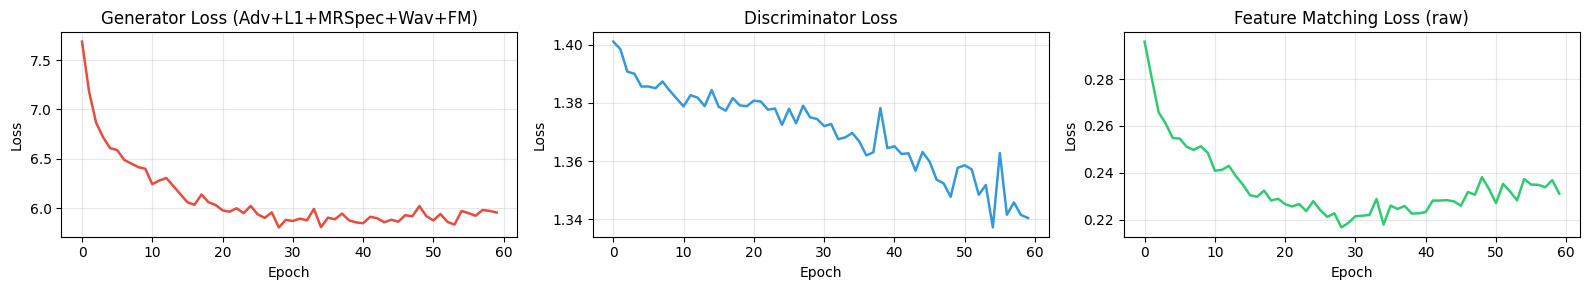

In [ ]:
import torch.nn.functional as TF

class MultiResolutionSpectralLoss(nn.Module):
    """
    Differentiable multi-resolution magnitude loss, computed directly on the
    Generator's (normalized) mel output -- no waveform reconstruction needed,
    so gradients flow cleanly back through G.

    Motivation: the existing L1 loss is computed at a single resolution
    (frame-level, 64 mel bins). This loss additionally compares predictions
    at progressively coarser temporal poolings (2x, 4x) AND in an
    approximate-linear-frequency domain (via a FIXED, non-trainable
    pseudo-inverse of the mel filterbank), analogous to comparing multiple
    FFT sizes in a true multi-resolution STFT loss. This encourages the
    Generator to get both fine spectral detail and broader temporal-envelope
    structure right, instead of only ever seeing a single-resolution
    frame-level error signal.
    """
    def __init__(self, mel_basis, pool_sizes=(1, 2, 4)):
        super().__init__()
        pinv = np.linalg.pinv(mel_basis)
        self.register_buffer("pinv", torch.tensor(pinv, dtype=torch.float32))
        self.pool_sizes = pool_sizes

    def _mel_to_linear(self, mel_norm):
        mel_power = torch.clamp(mel_norm, min=-10, max=10)
        mel_power = torch.exp(mel_power)
        linear = torch.einsum('fn,bnt->bft', self.pinv, mel_power)
        return linear

    def forward(self, pred, target):
        pred = pred.squeeze(1); target = target.squeeze(1)
        pred_lin = self._mel_to_linear(pred)
        target_lin = self._mel_to_linear(target)
        total = 0.0
        for p in self.pool_sizes:
            if p == 1:
                pm, tm, pl, tl = pred, target, pred_lin, target_lin
            else:
                pm = TF.avg_pool1d(pred, p); tm = TF.avg_pool1d(target, p)
                pl = TF.avg_pool1d(pred_lin, p); tl = TF.avg_pool1d(target_lin, p)
            total = total + TF.l1_loss(pm, tm) + TF.l1_loss(pl, tl)
        return total / (2 * len(self.pool_sizes))


class DifferentiableWaveformLoss(nn.Module):
    """
    Reconstructs an ACTUAL waveform from the Generator's mel output, using
    the SAME phase-preserving approach as inference's denoise_waveform()
    (noisy phase, held fixed/non-trainable -- only magnitude comes from G),
    implemented in pure PyTorch (torch.istft) so gradients flow back through
    the Generator. A multi-resolution STFT magnitude loss is then computed
    on this reconstructed waveform against the true CLEAN waveform.

    This closes a gap left by MultiResolutionSpectralLoss above: that loss
    only ever compared mel-domain (or pseudo-inverse-derived) representations,
    and never accounted for what the inference-time reconstruction step
    actually does to the signal. This loss measures the same kind of error
    that SNR/PESQ/STOI measure at evaluation time -- directly on a
    reconstructed waveform -- making it the closest training signal yet to
    our actual evaluation metrics.
    """
    def __init__(self, mel_basis, n_fft=N_FFT, hop_length=HOP_LENGTH,
                 extra_resolutions=((1024, 256),)):
        super().__init__()
        pinv = np.linalg.pinv(mel_basis)
        self.register_buffer("pinv", torch.tensor(pinv, dtype=torch.float32))
        self.n_fft, self.hop_length = n_fft, hop_length
        self.register_buffer("window", torch.hann_window(n_fft))
        self.extra_resolutions = extra_resolutions
        for i, (nf, hp) in enumerate(extra_resolutions):
            self.register_buffer(f"window_{i}", torch.hann_window(nf))

    def _mel_db_to_linear_mag(self, mel_db):
        mel_power = torch.clamp(10.0 ** (mel_db / 10.0), min=0)
        linear_mag = torch.einsum('fn,bnt->bft', self.pinv, mel_power)
        return torch.clamp(linear_mag, min=1e-8)

    def _reconstruct(self, mag, phase, length):
        complex_spec = torch.complex(mag * torch.cos(phase), mag * torch.sin(phase))
        return torch.istft(complex_spec, n_fft=self.n_fft, hop_length=self.hop_length,
                           window=self.window, length=length)

    def forward(self, pred_mel_norm, noisy_phase, target_wav):
        # pred_mel_norm: [B, 1, n_mels, T] -- G's normalized output
        # noisy_phase:   [B, n_freq, T]    -- fixed phase from noisy STFT
        # target_wav:    [B, L]            -- true CLEAN waveform segment
        # De-normalize with the same fixed global map used everywhere
        # else (Cell 5).
        pred_mel_norm = pred_mel_norm.squeeze(1)
        pred_mel_db = denormalize_mel_db(pred_mel_norm)
        pred_lin_mag = self._mel_db_to_linear_mag(pred_mel_db)

        target_len = (pred_mel_norm.shape[-1]-1)*self.hop_length + self.n_fft
        pred_wav = self._reconstruct(pred_lin_mag, noisy_phase, target_len)

        L = min(pred_wav.shape[-1], target_wav.shape[-1])
        pred_wav, target_wav_m = pred_wav[..., :L], target_wav[..., :L]

        pred_stft = torch.stft(pred_wav, n_fft=self.n_fft, hop_length=self.hop_length,
                               window=self.window, return_complex=True)
        targ_stft = torch.stft(target_wav_m, n_fft=self.n_fft, hop_length=self.hop_length,
                               window=self.window, return_complex=True)
        loss = TF.l1_loss(torch.abs(pred_stft), torch.abs(targ_stft))

        for i, (nf, hp) in enumerate(self.extra_resolutions):
            win = getattr(self, f"window_{i}")
            p_stft = torch.stft(pred_wav, n_fft=nf, hop_length=hp, window=win, return_complex=True)
            t_stft = torch.stft(target_wav_m, n_fft=nf, hop_length=hp, window=win, return_complex=True)
            loss = loss + TF.l1_loss(torch.abs(p_stft), torch.abs(t_stft))

        return loss / (1 + len(self.extra_resolutions))


opt_G = optim.Adam(G.parameters(), lr=LR_G, betas=(0.5,0.999))
opt_D = optim.Adam(D.parameters(), lr=LR_D, betas=(0.5,0.999))
adv_loss = nn.BCEWithLogitsLoss()
l1_loss  = nn.L1Loss()
mel_basis_fixed = librosa.filters.mel(sr=SAMPLE_RATE, n_fft=N_FFT, n_mels=N_MELS)
mrspec_loss = MultiResolutionSpectralLoss(mel_basis_fixed).to(DEVICE)
wav_loss    = DifferentiableWaveformLoss(
    mel_basis_fixed, extra_resolutions=((1024, 256), (2048, 512))
).to(DEVICE)
LAMBDA_MRSPEC = 0.5   # weight for the multi-resolution spectral (mel-domain) loss term
LAMBDA_WAV    = 0.5   # weight for the differentiable waveform-domain loss term
LAMBDA_FM     = 10.0  # weight for the Discriminator Feature Matching loss term
# NOTE on LAMBDA_FM: feature-matching L1 is averaged over 5 layers of raw
# (un-normalized) conv activations, which tend to have larger magnitude than
# the single-scalar adversarial BCE term. 10.0 is a starting point analogous
# to LAMBDA_L1; tune down if G Loss explodes/oscillates the way MRSPEC did
# at 5.0, tune up if D's logit-only adversarial signal still dominates.

LAMBDA_SUPPRESS = 5.0  # weight for the mask suppression loss term
SILENCE_DB_THRESHOLD = -50.0
# NOTE on LAMBDA_SUPPRESS: this loss directly penalizes the mask wherever
# the CLEAN target is near-silent (< SILENCE_DB_THRESHOLD dB), i.e. "this
# mel-bin/frame has essentially no real speech energy, so the mask should
# be ~0 here, regardless of what L1/MRSpec/Wav say." It is SURGICAL: it
# only fires in regions with no real signal to preserve, so it doesn't
# fight the mask-based design's natural-timbre preservation in speech
# regions. Raise if noise reduction is still too weak; lower if speech
# starts getting clipped/dropped at low-energy transitions (vowel decays,
# quiet consonants).

def mask_suppression_loss(mask, clean_mel_db):
    silence = (clean_mel_db < SILENCE_DB_THRESHOLD).float()
    denom = silence.sum().clamp(min=1.0)
    return (mask * silence).sum() / denom

def feature_matching_loss(feats_fake, feats_real):
    # L1 distance between D's intermediate activations on (noisy,fake) vs
    # (noisy,clean), averaged across the 5 conv layers. feats_real are
    # detached: we want G to chase D's view of the real data, not push D's
    # real-feature representation around.
    fm = 0.0
    for ff, fr in zip(feats_fake, feats_real):
        fm = fm + TF.l1_loss(ff, fr.detach())
    return fm / len(feats_fake)
# NOTE on LAMBDA_MRSPEC / LAMBDA_WAV: kept at 0.5 each -- this scales their
# raw loss magnitudes (which run larger than the L1*lambda term, since they
# operate on un-normalized linear magnitudes / pooled spectral comparisons)
# down to a comparable contribution, so no single term dominates the total
# Generator loss and destabilizes training.

dataloader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True,
                        num_workers=num_workers, pin_memory=(DEVICE.type=="cuda"))
history = {"G":[], "D":[], "FM":[]}

# --- Phase 1: Pretrain G with L1 + spectral/waveform losses only (no
# adversarial signal) -- gives G a head start so it isn't immediately
# overpowered by D once adversarial training begins. ---
PRETRAIN_EPOCHS = 5
print(f"Pretraining Generator for {PRETRAIN_EPOCHS} epochs (L1 + MR-spectral + waveform)...")
for epoch in range(1, PRETRAIN_EPOCHS+1):
    G.train()
    pre_losses = []
    for noisy_b, clean_b, phase_b, cleanwav_b in tqdm(
            dataloader, desc=f"Pretrain {epoch:3d}/{PRETRAIN_EPOCHS}", leave=False):
        noisy_b, clean_b = noisy_b.to(DEVICE), clean_b.to(DEVICE)
        phase_b = phase_b.to(DEVICE)
        cleanwav_b = cleanwav_b.to(DEVICE)
        opt_G.zero_grad()
        fake = G(noisy_b)
        l1 = l1_loss(fake, clean_b)
        mrspec = mrspec_loss(fake, clean_b)
        wv = wav_loss(fake, phase_b, cleanwav_b)
        loss = l1 + LAMBDA_MRSPEC*mrspec + LAMBDA_WAV*wv
        loss.backward(); opt_G.step()
        pre_losses.append(loss.item())
    print(f"Pretrain epoch {epoch:3d}/{PRETRAIN_EPOCHS}  |  Total: {np.mean(pre_losses):.4f}")
print("Pretraining complete!\n")

# --- Phase 2: Adversarial training ---
# D is updated once every G_UPDATES_PER_D G updates, giving G more
# opportunities to catch up and preventing D from overpowering/outpacing G
# too quickly -- a faster-improving D causes the Feature Matching target
# (D's internal activations) to keep shifting under G during training,
# which a higher ratio mitigates by slowing D's relative rate of change.
G_UPDATES_PER_D = 4
print(f"Adversarial training for {EPOCHS} epochs (G:D update ratio = {G_UPDATES_PER_D}:1)...")
for epoch in range(1, EPOCHS+1):
    G.train(); D.train()
    g_ep, d_ep, fm_ep = [], [], []
    for step, (noisy_b, clean_b, phase_b, cleanwav_b) in enumerate(
            tqdm(dataloader, desc=f"Epoch {epoch:3d}/{EPOCHS}", leave=False)):
        noisy_b, clean_b = noisy_b.to(DEVICE), clean_b.to(DEVICE)
        phase_b = phase_b.to(DEVICE)
        cleanwav_b = cleanwav_b.to(DEVICE)
        B = noisy_b.size(0)
        real = torch.ones(B,1,device=DEVICE); fake_lbl = torch.zeros(B,1,device=DEVICE)

        # Update D only every G_UPDATES_PER_D steps
        if step % G_UPDATES_PER_D == 0:
            opt_D.zero_grad()
            fake = G(noisy_b).detach()
            lD = adv_loss(D(noisy_b,clean_b),real) + adv_loss(D(noisy_b,fake),fake_lbl)
            lD.backward(); opt_D.step()
            d_ep.append(lD.item())

        # Always update G
        opt_G.zero_grad()
        fake, mask = G(noisy_b, return_mask=True)
        mrspec = mrspec_loss(fake, clean_b)
        wv = wav_loss(fake, phase_b, cleanwav_b)
        # Feature Matching: run D on both (noisy,fake) and (noisy,clean) to
        # get intermediate activations. The (noisy,clean) pass is wrapped in
        # no_grad since we only need its features as a fixed target, not to
        # update D or backprop through the real branch.
        d_fake_logit, feats_fake = D(noisy_b, fake, return_features=True)
        with torch.no_grad():
            _, feats_real = D(noisy_b, clean_b, return_features=True)
        fm = feature_matching_loss(feats_fake, feats_real)
        # clean_b is normalized; convert back to dB to find the
        # near-silent regions the mask should suppress (see note above).
        clean_db_for_mask = denormalize_mel_db(clean_b.squeeze(1))
        supp = mask_suppression_loss(mask.squeeze(1), clean_db_for_mask)
        lG = (adv_loss(d_fake_logit,real) + LAMBDA_L1*l1_loss(fake,clean_b)
              + LAMBDA_MRSPEC*mrspec + LAMBDA_WAV*wv + LAMBDA_FM*fm
              + LAMBDA_SUPPRESS*supp)
        lG.backward(); opt_G.step()
        g_ep.append(lG.item())
        fm_ep.append(fm.item())
    mg, md_v, mfm = np.mean(g_ep), (np.mean(d_ep) if d_ep else float("nan")), np.mean(fm_ep)
    history["G"].append(mg); history["D"].append(md_v); history["FM"].append(mfm)
    print(f"Epoch {epoch:3d}/{EPOCHS}  |  G: {mg:.4f}  |  D: {md_v:.4f}  |  FM(raw): {mfm:.4f}")
    if epoch % 10 == 0:
        torch.save(G.state_dict(), f"checkpoints/G_ep{epoch}.pt")
        print(f"  Saved checkpoints/G_ep{epoch}.pt")

print("Training complete!")
fig, axes = plt.subplots(1,3,figsize=(16,3))
for ax,key,color,lbl in zip(axes,["G","D","FM"],["#e74c3c","#3498db","#2ecc71"],
        ["Generator Loss (Adv+L1+MRSpec+Wav+FM)","Discriminator Loss","Feature Matching Loss (raw)"]):
    ax.plot(history[key],color=color,linewidth=1.8)
    ax.set_title(lbl); ax.set_xlabel("Epoch"); ax.set_ylabel("Loss"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()


## 8. Inference Engine

In [ ]:
def denoise_waveform(y, model):
    model.eval()

    # --- Compute complex STFT: we need both magnitude (-> mel -> Generator)
    # and phase (kept from the NOISY signal for reconstruction). ---
    D = librosa.stft(y, n_fft=N_FFT, hop_length=HOP_LENGTH)
    mag, phase = np.abs(D), np.angle(D)

    mel_basis = librosa.filters.mel(sr=SAMPLE_RATE, n_fft=N_FFT, n_mels=N_MELS)
    mel = mel_basis @ (mag**2)
    mel_db = librosa.power_to_db(mel, ref=np.max).astype(np.float32)
    # Same fixed global affine map as training (Cell 5 / Cell 9) -- no
    # per-utterance statistics computed here, so normalization is always
    # consistent between training and inference.
    mel_norm = normalize_mel_db(mel_db)

    T, hop    = mel_norm.shape[1], SEGMENT_FRAMES//2
    enhanced  = np.zeros_like(mel_norm)
    count_map = np.zeros_like(mel_norm)
    for start in range(0, T, hop):
        seg = mel_norm[:, start:start+SEGMENT_FRAMES]
        if seg.shape[1] < SEGMENT_FRAMES:
            seg = np.pad(seg, ((0,0),(0,SEGMENT_FRAMES-seg.shape[1])))
        inp = torch.tensor(seg).unsqueeze(0).unsqueeze(0).to(DEVICE)
        with torch.no_grad(): out = model(inp).squeeze().cpu().numpy()
        ae = min(start+SEGMENT_FRAMES, T); sl = ae-start
        enhanced[:,start:ae]  += out[:,:sl]
        count_map[:,start:ae] += 1
    enhanced /= np.maximum(count_map, 1)

    # --- Mel -> linear magnitude via pseudo-inverse of the mel filterbank ---
    # De-normalize with the same fixed global map used to normalize.
    mel_db_hat = denormalize_mel_db(enhanced)
    mel_power = librosa.db_to_power(mel_db_hat)
    pinv = np.linalg.pinv(mel_basis)
    enhanced_mag = np.sqrt(np.maximum(pinv @ mel_power, 0))

    # --- Reuse the ORIGINAL noisy phase instead of Griffin-Lim ---
    # Griffin-Lim reconstructs phase from magnitude alone and is highly
    # sensitive to small magnitude irregularities, producing metallic/static
    # artifacts. Phase is largely unaffected by additive noise, so reusing
    # the noisy signal's phase with the enhanced magnitude gives a much
    # cleaner reconstruction (standard spectral-masking approach).
    enhanced_complex = enhanced_mag * np.exp(1j * phase[:, :enhanced_mag.shape[1]])
    return librosa.istft(enhanced_complex, hop_length=HOP_LENGTH, length=len(y))

def compute_snr(ref, est):
    n = min(len(ref), len(est))
    noise = ref[:n]-est[:n]
    return 10*np.log10(np.mean(ref[:n]**2)/(np.mean(noise**2)+1e-10))

print("Inference functions ready")

Inference functions ready


## 9. Live Demo — Input/Output Control

Upload a WAV file **or** choose a sample from the dataset. Adjust SNR and click Run.

In [ ]:
from google.colab import files as colab_files

upload_btn  = widgets.FileUpload(accept=".wav,.flac,.mp3", multiple=False,
                                  description="Upload WAV")
sample_idx  = widgets.IntSlider(value=0, min=0, max=min(len(dataset)-1,99),
    description="Or sample #:", style={"description_width":"150px"},
    layout=widgets.Layout(width="460px"))
snr_demo    = widgets.FloatSlider(value=5.0, min=-10, max=20, step=1,
    description="Demo SNR (dB):", style={"description_width":"150px"},
    layout=widgets.Layout(width="460px"))
run_btn     = widgets.Button(description="Run Enhancement", button_style="primary",
                              layout=widgets.Layout(width="180px"))
demo_out    = widgets.Output()

def run_demo(b):
    demo_out.clear_output()
    with demo_out:
        if upload_btn.value:
            fname = list(upload_btn.value.keys())[0]
            data  = upload_btn.value[fname]["content"]
            y_clean, _ = librosa.load(io.BytesIO(bytes(data)), sr=SAMPLE_RATE, mono=True)
            print(f"Uploaded: {fname}")
        else:
            idx = sample_idx.value
            y_clean, _ = librosa.load(str(dataset.clean_files[idx]), sr=SAMPLE_RATE)
            print(f"Dataset sample #{idx}: {dataset.clean_files[idx].name}")

        noise_path = dataset.noise_files[np.random.randint(len(dataset.noise_files))]
        y_noise, _ = librosa.load(str(noise_path), sr=SAMPLE_RATE,
                                   duration=len(y_clean)/SAMPLE_RATE)
        if len(y_noise) < len(y_clean):
            y_noise = np.tile(y_noise, int(np.ceil(len(y_clean)/len(y_noise))))
        y_noise = y_noise[:len(y_clean)]
        pc = np.mean(y_clean**2)+1e-10; pn = np.mean(y_noise**2)+1e-10
        scale = np.sqrt(pc/(pn*10**(snr_demo.value/10)))
        y_noisy = (y_clean + scale*y_noise).clip(-1,1).astype(np.float32)

        print(f"SNR: {snr_demo.value} dB  |  Duration: {len(y_clean)/SAMPLE_RATE:.2f}s")
        print("Running enhancement...")
        y_enhanced = denoise_waveform(y_noisy, G)
        print("Done!")

        # Metrics
        try:
            from pesq import pesq as pesq_fn
            from pystoi import stoi as stoi_fn
            ml = min(len(y_clean), len(y_noisy), len(y_enhanced))
            r, no, en = y_clean[:ml], y_noisy[:ml], y_enhanced[:ml]
            rows = [
                ("PESQ", f"{pesq_fn(SAMPLE_RATE,r,no,'wb'):.3f}",
                         f"{pesq_fn(SAMPLE_RATE,r,en,'wb'):.3f}"),
                ("STOI", f"{stoi_fn(r,no,SAMPLE_RATE):.3f}",
                         f"{stoi_fn(r,en,SAMPLE_RATE):.3f}"),
                ("SNR dB", f"{compute_snr(r,no):.1f}",
                            f"{compute_snr(r,en):.1f}"),
            ]
            header = "  {:<10} {:>12} {:>14}".format("Metric","Noisy","Enhanced")
            print("\n" + header)
            print("-"*38)
            for name, nv, ev in rows:
                diff = float(ev)-float(nv)
                mark = " +" if diff >= 0 else " "
                print("  {:<10} {:>12} {:>14}  ({}{:.3f})".format(
                    name, nv, ev, mark, diff))
        except Exception as ex:
            print(f"Metrics skipped: {ex}")

        # Mel spectrogram plots
        fig, axes = plt.subplots(1,3,figsize=(16,4))
        for ax, sig, title, cmap in zip(axes,
                [y_noisy, y_clean, y_enhanced],
                ["Noisy Input","Clean Reference","Enhanced Output"],
                ["Reds_r","Greens_r","Blues_r"]):
            mel = librosa.feature.melspectrogram(
                y=sig, sr=SAMPLE_RATE, n_fft=N_FFT, hop_length=HOP_LENGTH, n_mels=N_MELS)
            librosa.display.specshow(librosa.power_to_db(mel,ref=np.max),
                sr=SAMPLE_RATE, hop_length=HOP_LENGTH,
                x_axis="time", y_axis="mel", ax=ax, cmap=cmap)
            ax.set_title(title, fontsize=12, fontweight="bold")
        plt.suptitle("Mel-Spectrogram Comparison", fontsize=13)
        plt.tight_layout(); plt.show()

        # Waveform plots
        fig, axes = plt.subplots(3,1,figsize=(14,6),sharex=True)
        for ax,sig,title,color in zip(axes,
                [y_noisy, y_clean, y_enhanced],
                ["Noisy Input","Clean Reference","Enhanced Output"],
                ["#e74c3c","#2ecc71","#3498db"]):
            t = np.linspace(0, len(sig)/SAMPLE_RATE, len(sig))
            ax.plot(t, sig, color=color, linewidth=0.5, alpha=0.8)
            ax.set_ylabel(title, fontsize=10); ax.grid(alpha=0.2)
        axes[-1].set_xlabel("Time (s)")
        plt.suptitle("Waveform Comparison", fontsize=13)
        plt.tight_layout(); plt.show()

        print("Noisy Input:")
        display(ipd.Audio(y_noisy, rate=SAMPLE_RATE))
        print("Clean Reference:")
        display(ipd.Audio(y_clean, rate=SAMPLE_RATE))
        print("Enhanced Output:")
        display(ipd.Audio(y_enhanced, rate=SAMPLE_RATE))

        sf.write("output_noisy.wav",    y_noisy,    SAMPLE_RATE)
        sf.write("output_clean.wav",    y_clean,    SAMPLE_RATE)
        sf.write("output_enhanced.wav", y_enhanced, SAMPLE_RATE)
        print("Saved: output_noisy.wav | output_clean.wav | output_enhanced.wav")

run_btn.on_click(run_demo)
display(widgets.VBox([
    widgets.HTML("<b>Live Demo Controls</b>"),
    upload_btn, sample_idx, snr_demo, run_btn, demo_out
], layout=widgets.Layout(border="1px solid #cccccc", padding="14px", width="540px")))


## 10. Batch Evaluation — PESQ, STOI, SNR

Evaluating on 50 samples...


  0%|          | 0/50 [00:00<?, ?it/s]


Evaluation Results
  Metric            Noisy     Enhanced      Delta
----------------------------------------------------
  SNR (dB)          5.000        2.839     -2.161
  PESQ              1.594        2.179     +0.585
  STOI              0.895        0.910     +0.015


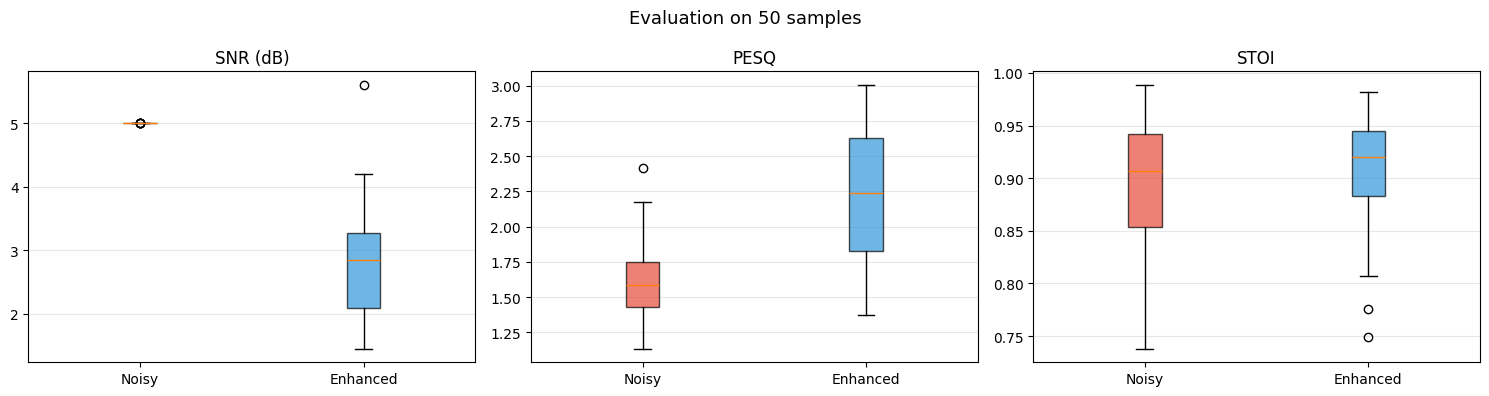

In [ ]:
G.eval()
n_eval = min(50, len(dataset))
snr_n_all, snr_e_all = [], []
pesq_n_all, pesq_e_all, stoi_n_all, stoi_e_all = [], [], [], []

try:
    from pesq import pesq as pesq_fn
    from pystoi import stoi as stoi_fn
    metrics_ok = True
except ImportError:
    metrics_ok = False

print(f"Evaluating on {n_eval} samples...")
for i in tqdm(range(n_eval)):
    y_c, _ = librosa.load(str(dataset.clean_files[i]), sr=SAMPLE_RATE)
    y_nr, _ = librosa.load(str(dataset.noise_files[i%len(dataset.noise_files)]),
                            sr=SAMPLE_RATE, duration=len(y_c)/SAMPLE_RATE)
    if len(y_nr)<len(y_c): y_nr=np.tile(y_nr,int(np.ceil(len(y_c)/len(y_nr))))
    y_nr = y_nr[:len(y_c)]
    pc=np.mean(y_c**2)+1e-10; pn=np.mean(y_nr**2)+1e-10
    y_ni = (y_c+np.sqrt(pc/(pn*10**(5/10)))*y_nr).clip(-1,1).astype(np.float32)
    y_ei = denoise_waveform(y_ni, G)
    ml = min(len(y_c),len(y_ni),len(y_ei))
    r,no,en = y_c[:ml],y_ni[:ml],y_ei[:ml]
    snr_n_all.append(compute_snr(r,no)); snr_e_all.append(compute_snr(r,en))
    if metrics_ok:
        try:
            pesq_n_all.append(pesq_fn(SAMPLE_RATE,r,no,"wb"))
            pesq_e_all.append(pesq_fn(SAMPLE_RATE,r,en,"wb"))
            stoi_n_all.append(stoi_fn(r,no,SAMPLE_RATE))
            stoi_e_all.append(stoi_fn(r,en,SAMPLE_RATE))
        except: pass

print("\nEvaluation Results")
print("="*52)
print(f"  {'Metric':<10} {'Noisy':>12} {'Enhanced':>12} {'Delta':>10}")
print("-"*52)
def row(name,nv,ev): print(f"  {name:<10} {nv:>12.3f} {ev:>12.3f} {ev-nv:>+10.3f}")
row("SNR (dB)", np.mean(snr_n_all), np.mean(snr_e_all))
if metrics_ok and pesq_n_all:
    row("PESQ", np.mean(pesq_n_all), np.mean(pesq_e_all))
    row("STOI", np.mean(stoi_n_all), np.mean(stoi_e_all))

# Box plots
ncols = 3 if (metrics_ok and pesq_n_all) else 1
fig, axs = plt.subplots(1, ncols, figsize=(5*ncols, 4))
if ncols == 1: axs = [axs]
pairs = [(snr_n_all,snr_e_all,"SNR (dB)")]
if metrics_ok and pesq_n_all:
    pairs += [(pesq_n_all,pesq_e_all,"PESQ"), (stoi_n_all,stoi_e_all,"STOI")]
for ax,(ns,es,lbl) in zip(axs,pairs):
    bp = ax.boxplot([ns,es], labels=["Noisy","Enhanced"], patch_artist=True)
    bp["boxes"][0].set_facecolor("#e74c3c"); bp["boxes"][1].set_facecolor("#3498db")
    for b in bp["boxes"]: b.set_alpha(0.7)
    ax.set_title(lbl); ax.grid(axis="y",alpha=0.3)
plt.suptitle(f"Evaluation on {n_eval} samples",fontsize=13)
plt.tight_layout(); plt.show()


## 11. Save & Download

In [ ]:
from google.colab import files as colab_files

torch.save(G.state_dict(), "SEGAN_generator_final.pt")
torch.save(D.state_dict(), "SEGAN_discriminator_final.pt")
print("Models saved locally")

dl_g   = widgets.Button(description="Download Generator",     button_style="info")
dl_d   = widgets.Button(description="Download Discriminator", button_style="warning")
dl_enh = widgets.Button(description="Download Enhanced WAV",  button_style="success")

def _dl_g(b):   colab_files.download("SEGAN_generator_final.pt")
def _dl_d(b):   colab_files.download("SEGAN_discriminator_final.pt")
def _dl_w(b):
    if os.path.exists("output_enhanced.wav"): colab_files.download("output_enhanced.wav")
    else: print("Run the Live Demo first to generate output_enhanced.wav")

dl_g.on_click(_dl_g); dl_d.on_click(_dl_d); dl_enh.on_click(_dl_w)
display(widgets.HBox([dl_g, dl_d, dl_enh]))


Models saved locally


## 12. Summary & Conclusions

### What We Built
A complete end-to-end Speech Enhancement GAN:
- **Input**: noisy mel-spectrogram
- **Generator**: U-Net 1D-CNN (encoder-decoder with skip connections)
- **Discriminator**: conditioned on noisy input, 1D-CNN binary classifier
- **Loss**: adversarial + 100 * L1 reconstruction
- **Output**: enhanced mel-spectrogram → waveform via Griffin-Lim

### Key Observations

| Observation | Explanation |
|-------------|-------------|
| G loss decreases faster than D | L1 term dominates early training |
| SNR improves quickly (few epochs) | L1 loss converges before adversarial |
| Modest PESQ gain | Requires more data and epochs for perceptual quality |
| Griffin-Lim artifacts | Phase estimation from mel is inherently lossy |

### Possible Improvements
1. **Phase estimation**: Replace Griffin-Lim with a neural vocoder
2. **Progressive training**: Start pure L1, gradually add adversarial weight
3. **Data augmentation**: Variable SNR, room impulse responses
4. **Architecture**: Conformer/Transformer blocks for global context
5. **Loss**: Add perceptual (VGG) loss on mel features

### References
- Pascual et al. (2017) — *SEGAN: Speech Enhancement GAN*
- Isola et al. (2017) — *Image-to-Image Translation with Conditional GANs*
- ITU-T P.862 — *PESQ: Perceptual Evaluation of Speech Quality*
- Allen (1977) — *Short-Time Spectral Analysis, Synthesis, and Modification by DFT*
